# PyCUDA and cuFFT: FFT and inverse FFT

Analyze a signal with known frequency components, compare its FFT with NumPy and analytical Fourier coefficients, and reconstruct it by inverse FFT. An optional two-dimensional example extends the same operations to a field. No custom CUDA kernel is written.

Run cells in order in a Google Colab GPU runtime. All figures and printouts stay in the notebook; no result files are exported. This is an introductory correctness experiment, not a CPU/GPU speed benchmark.

PyCUDA owns the GPU arrays and transfers; **cuFFT**, called through NVIDIA `nvmath.bindings`, performs the numerical operation. These bindings are a separate package, not part of PyCUDA. The examples do not call CuPy.

## 1. Prepare a fresh Google Colab GPU runtime

Choose **Runtime → Change runtime type → GPU**. Run the setup before imports. It installs PyCUDA and pins nvmath-python 1.0.0, with the CUDA 12 or 13 dependencies matching the runtime toolkit. Installation can take several minutes. A compatible NVIDIA driver and `nvcc` are still required. The low-level bindings are documented as experimental, so the package version is fixed rather than silently taking an arbitrary future release.

Use a fresh runtime for this notebook; do not mix `pycuda.autoinit` from an earlier notebook with the primary-context initialization used here.

In [11]:
import re
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

# Run this cell before importing PyCUDA or nvmath in a fresh GPU runtime.
subprocess.run(["nvidia-smi"], check=True)
info = subprocess.check_output(["nvcc", "--version"], text=True)
print(info)
match = re.search(r"release\s+(\d+)\.", info)
if not match or int(match.group(1)) not in (12, 13):
    raise RuntimeError("This notebook setup targets CUDA 12 or 13.")
major = int(match.group(1))
requirements = ["pycuda", f"nvmath-python[cu{major}]==1.0.0"]
subprocess.check_call([sys.executable, "-m", "pip", "install", *requirements])
print("Setup complete. If Colab asks for a runtime restart, restart before proceeding.")

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0

Setup complete. If Colab asks for a runtime restart, restart before proceeding.


## 2. Imports and validation

The primary CUDA context is shared by the PyCUDA allocations and library calls. All work uses the default stream; the examples wait for completion before destroying library resources. Double precision and the same input formulas as in the CuPy notebook permit like-for-like correctness checks.

In [12]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoprimaryctx  # keep one primary context current for these libraries
import pycuda.gpuarray as gpuarray
import nvmath
from importlib.metadata import version

print("GPU:", cuda.Context.get_device().name())
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "PyCUDA:", version("pycuda"),
      "nvmath-python:", version("nvmath-python"))
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

def ptr(a):
    # The owner must remain alive while the library uses its device storage.
    return int(a.gpudata)

GPU: Tesla T4
Python: 3.13.15
NumPy: 2.1.3 PyCUDA: 2026.1 nvmath-python: 1.0.0


In [13]:
def check(label, result, reference, rtol=1e-11, atol=1e-11):
    assert result.shape == reference.shape, (result.shape, reference.shape)
    assert result.dtype == reference.dtype, (result.dtype, reference.dtype)
    if not np.all(np.isfinite(result)):
        raise AssertionError(f"{label}: nonfinite result")
    np.testing.assert_allclose(result, reference, rtol=rtol, atol=atol)
    error = np.max(np.abs(result-reference))
    relative = np.linalg.norm((result-reference).ravel()) / max(np.linalg.norm(reference.ravel()), np.finfo(float).tiny)
    print(f"{label}: validated; max absolute error={error:.3e}; relative norm error={relative:.3e}")

### Library bridge: a reusable FFT helper

Run the next cell once. `fft_gpu` is a helper defined in this notebook, not a PyCUDA API. cuFFT receives the addresses of existing GPUArray buffers and a plan specifying shape and type. The full complex transform is used for a direct comparison with the CuPy example. **cuFFT does not normalize its inverse**; the helper divides by the total number of samples on the GPU.

In [14]:
from nvmath.bindings import cufft

def fft_gpu(a, inverse=False):
    """Full complex FFT for C-contiguous complex128 vectors or matrices."""
    if a.dtype != np.complex128 or len(a.shape) not in (1, 2) or not a.flags.c_contiguous:
        raise ValueError("Expected a C-contiguous complex128 vector or matrix")
    if any(d <= 0 or d > np.iinfo(np.int32).max for d in a.shape):
        raise ValueError("Transform dimensions must fit positive 32-bit integers")
    result = gpuarray.empty(a.shape, np.complex128)
    plan = cufft.create()
    try:
        if len(a.shape) == 1:
            cufft.make_plan1d(plan, a.shape[0], cufft.Type.Z2Z, 1)
        else:
            cufft.make_plan2d(plan, a.shape[0], a.shape[1], cufft.Type.Z2Z)
        cufft.set_stream(plan, 0)
        # cuFFT direction constants: forward=-1, inverse=+1.
        cufft.exec_z2z(plan, ptr(a), ptr(result), 1 if inverse else -1)
        if inverse:
            result *= np.float64(1.0 / a.size)
        cuda.Context.synchronize()
    finally:
        cufft.destroy(plan)
    return result

## 3. Construct a known signal

Sample $u(t)=0.2+\cos(2\pi50t)+0.5\sin(2\pi120t)$ at 1024 samples/s for one second, **excluding** the repeated endpoint. The 50 Hz and 120 Hz components lie exactly on DFT bins, avoiding spectral leakage in this example. Their frequencies are below the Nyquist frequency, 512 Hz.

In [15]:
N = 1024
fs = 1024.0
t = np.arange(N, dtype=np.float64) / fs
h_u = 0.2 + np.cos(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*120*t)
assert h_u.dtype == np.float64
U_cpu = np.fft.fft(h_u, norm="backward")
# Analytical DFT coefficients for these bin-aligned harmonics.
U_expected = np.zeros(N, dtype=np.complex128)
U_expected[0] = 0.2*N
U_expected[50] = U_expected[-50] = N/2
U_expected[120] = -0.25j*N
U_expected[-120] = 0.25j*N
check("NumPy FFT vs analytical coefficients", U_cpu, U_expected)

NumPy FFT vs analytical coefficients: validated; max absolute error=1.105e-11; relative norm error=2.474e-14


## 4. Transform and reconstruct on the GPU

Convert the real samples to complex128 before transferring them with `gpuarray.to_gpu`. `fft_gpu` produces a full complex spectrum and its normalized inverse. The spectrum remains on the GPU between calls. `.get()` explicitly retrieves the results for validation and plotting.

Do not discard the imaginary reconstruction component before checking it. The helper normalizes the inverse, so no second division is needed here.

In [16]:
d_u = gpuarray.to_gpu(h_u.astype(np.complex128))
d_U = fft_gpu(d_u)
d_reconstructed = fft_gpu(d_U, inverse=True)
U_gpu = d_U.get()
u_reconstructed = d_reconstructed.get()
check("GPU FFT vs NumPy", U_gpu, U_cpu)
check("GPU FFT vs analytical coefficients", U_gpu, U_expected)
check("Inverse reconstruction", u_reconstructed, h_u.astype(np.complex128))
print("Maximum imaginary reconstruction component:", np.max(np.abs(u_reconstructed.imag)))
print(f"{'Frequency (Hz)':>16} {'DFT coefficient / N':>27}")
for k in [0,50,120]:
    print(f"{k*fs/N:16.1f} {U_gpu[k]/N!s:>27}")

GPU FFT vs NumPy: validated; max absolute error=1.137e-13; relative norm error=3.290e-16
GPU FFT vs analytical coefficients: validated; max absolute error=1.107e-11; relative norm error=2.474e-14
Inverse reconstruction: validated; max absolute error=7.555e-16; relative norm error=4.259e-16
Maximum imaginary reconstruction component: 7.077671781985386e-16
  Frequency (Hz)         DFT coefficient / N
             0.0     (0.1999999999999997+0j)
            50.0 (0.5000000000000002+5.756888505727058e-16j)
           120.0 (-1.0813236763857465e-14-0.25000000000000006j)


## 5. Display the spectrum and reconstruction

For this even-length real signal, the one-sided amplitude spectrum divides magnitudes by N and doubles only the interior positive-frequency bins. DC and Nyquist are not doubled. This plotting convention differs from the normalization of the raw FFT coefficients.

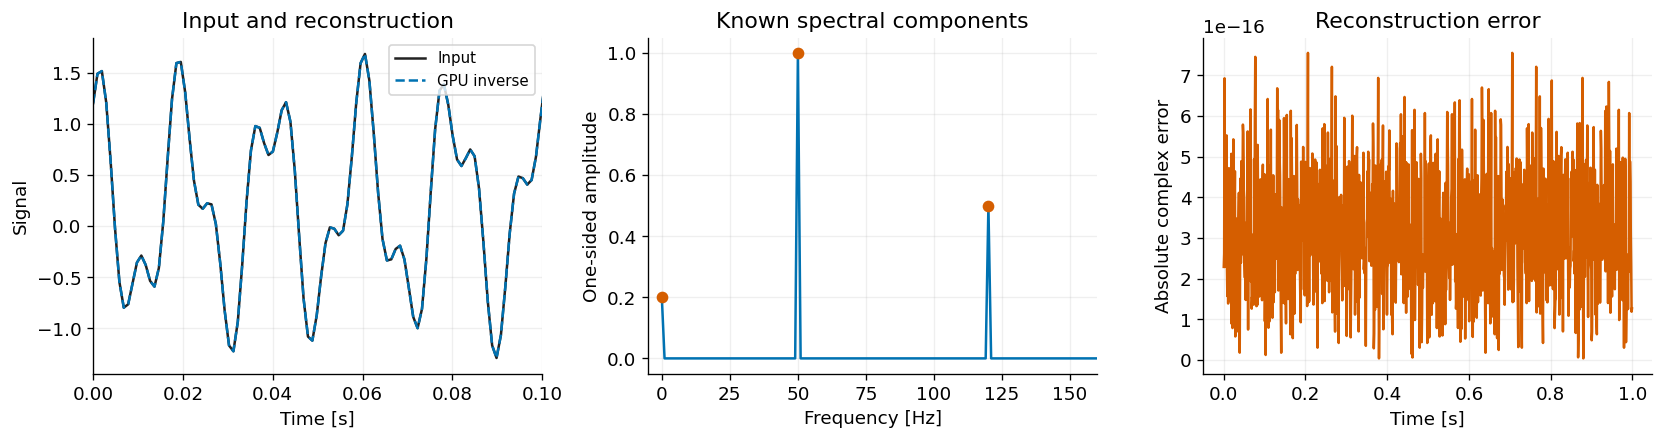

In [17]:
frequency = np.fft.rfftfreq(N, d=1/fs)
amplitude = np.abs(U_gpu[:N//2+1]) / N
amplitude[1:-1] *= 2
np.testing.assert_allclose(amplitude[[0,50,120]], [0.2,1.0,0.5], rtol=1e-11, atol=1e-11)
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
axes[0].plot(t,h_u,color='#222222',label='Input')
axes[0].plot(t,u_reconstructed.real,'--',color='#0072B2',label='GPU inverse')
axes[0].set(xlim=(0,0.1),xlabel='Time [s]',ylabel='Signal',title='Input and reconstruction')
axes[0].legend(fontsize=9)
axes[1].plot(frequency,amplitude,color='#0072B2')
axes[1].scatter([0,50,120],amplitude[[0,50,120]],color='#D55E00',zorder=3)
axes[1].set(xlim=(-5,160),xlabel='Frequency [Hz]',ylabel='One-sided amplitude',title='Known spectral components')
axes[2].plot(t,np.abs(u_reconstructed-h_u),color='#D55E00')
axes[2].set(xlabel='Time [s]',ylabel='Absolute complex error',title='Reconstruction error')
axes[2].ticklabel_format(axis='y',style='sci',scilimits=(0,0))
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

## 6. Optional: a two-dimensional periodic field

Construct $v(x,y)=\cos(2\pi3x)+0.5\sin(2\pi5y)$ on $[0,1)^2$. Rows correspond to y and columns to x. The same helper transforms both axes for a two-dimensional input; the inverse normalization divides by their size product. `fftshift` is used **only for plotting**, not as input to the inverse.

In [18]:
nx, ny = 128, 96
x = np.arange(nx,dtype=np.float64)/nx
y = np.arange(ny,dtype=np.float64)/ny
h_v = np.cos(2*np.pi*3*x)[None,:] + 0.5*np.sin(2*np.pi*5*y)[:,None]
d_v = gpuarray.to_gpu(h_v.astype(np.complex128))
d_V = fft_gpu(d_v)
d_v_back = fft_gpu(d_V, inverse=True)
V_gpu = d_V.get()
v_back = d_v_back.get()
check("2D FFT vs NumPy", V_gpu, np.fft.fft2(h_v,norm="backward"))
check("2D inverse", v_back, h_v.astype(np.complex128))
print("2D field shape (rows, columns):",h_v.shape)

2D FFT vs NumPy: validated; max absolute error=5.194e-13; relative norm error=2.564e-16
2D inverse: validated; max absolute error=8.885e-16; relative norm error=2.803e-16
2D field shape (rows, columns): (96, 128)


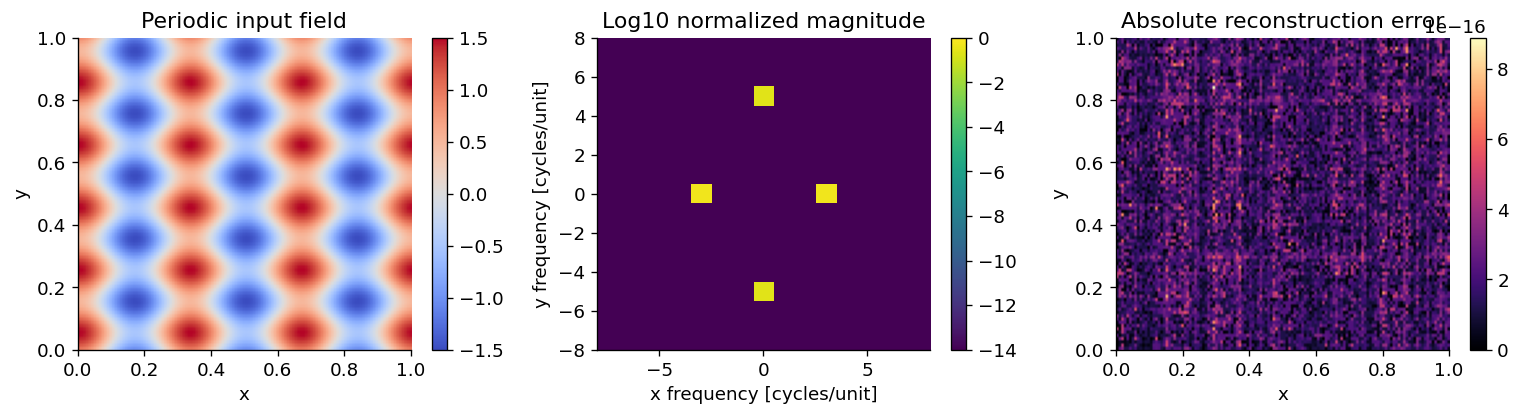

In [19]:
fig, axes = plt.subplots(1,3,figsize=(13,3.6))
im=axes[0].imshow(h_v,origin='lower',extent=(0,1,0,1),cmap='coolwarm',aspect='auto')
axes[0].set(xlabel='x',ylabel='y',title='Periodic input field')
fig.colorbar(im,ax=axes[0])
kx=np.fft.fftshift(np.fft.fftfreq(nx,d=1/nx))
ky=np.fft.fftshift(np.fft.fftfreq(ny,d=1/ny))
spectrum=np.abs(np.fft.fftshift(V_gpu))/(nx*ny)
im=axes[1].imshow(np.log10(np.maximum(spectrum,1e-14)),origin='lower',
    extent=(kx[0]-.5,kx[-1]+.5,ky[0]-.5,ky[-1]+.5),cmap='viridis',aspect='auto',vmin=-14,vmax=0)
axes[1].set(xlim=(-8,8),ylim=(-8,8),xlabel='x frequency [cycles/unit]',ylabel='y frequency [cycles/unit]',title='Log10 normalized magnitude')
fig.colorbar(im,ax=axes[1])
im=axes[2].imshow(np.abs(v_back-h_v),origin='lower',extent=(0,1,0,1),cmap='magma',aspect='auto')
axes[2].set(xlabel='x',ylabel='y',title='Absolute reconstruction error')
fig.colorbar(im,ax=axes[2])
fig.tight_layout()
plt.show()

## Interpretation and execution status

The arrays are owned by PyCUDA; the numerical operation is executed by the named NVIDIA library through nvmath bindings. Plan creation, handles, descriptors, and workspaces are explicit here, whereas CuPy normally manages them behind its array interface. These teaching helpers deliberately synchronize before releasing resources; they are not benchmark harnesses or optimized repeated-operation wrappers. A production solver would reuse compatible plans, handles, buffers and descriptors.

**Preparation status:** code syntax, CPU reference calculations, data-layout checks and plotting logic were checked. GPU execution and Colab package installation could not be tested in the preparation environment. No GPU outputs or timings are prefilled.

References: [PyCUDA GPUArray](https://documen.tician.de/pycuda/array.html), [NVIDIA nvmath bindings](https://docs.nvidia.com/cuda/nvmath-python/latest/bindings/index.html), [installation](https://docs.nvidia.com/cuda/nvmath-python/latest/installation.html).

## Cleanup

Library handles and descriptors are released by the helper functions after completion. Remove the remaining device arrays below. To repeat the experiment, rerun from data preparation.

In [20]:
cuda.Context.synchronize()
del d_u, d_U, d_reconstructed
for variable in ("d_v", "d_V", "d_v_back"):
    globals().pop(variable, None)
print("Device array references released.")

Device array references released.
